<a href="https://colab.research.google.com/github/Reapfan/Data-Analysis/blob/main/DA_CA_dbscan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
# Активация библиотек

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
import seaborn as sns
%matplotlib inline

import os
from sklearn import preprocessing
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [3]:
# Импорт файла целиком
from google.colab import files
uploaded = files.upload()

Saving Lolypops.dat to Lolypops.dat


In [4]:
# Чтение файла
df = pd.read_csv("/content/Lolypops.dat", sep=";")
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [5]:
# Основная информация
df.info()
# Наличие пропусков и дублей
print(df.isna().sum())
print('Число дублей:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
dtype: int64
Число дублей: 293


In [6]:
# Основные описательные статистики
desc = df.describe()
desc.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000
mean,3.544,3.527,3.518,3.411,3.207,3.204,3.254,3.290,3.604,3.550,3.565
std,0.956,0.956,0.990,0.992,0.867,0.870,0.844,0.822,0.970,0.927,0.942
min,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000
25%,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
50%,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
75%,5.000,5.000,5.000,4.000,3.000,3.000,3.000,3.000,5.000,5.000,5.000
max,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000


In [7]:
# Частота значений в каждом столбце
freq = df.apply(lambda s: s.value_counts(normalize=True).sort_index())
freq.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
2,0.056,0.071,0.092,0.148,0.139,0.142,0.101,0.074,0.044,0.044,0.044
3,0.618,0.592,0.571,0.515,0.669,0.666,0.704,0.722,0.612,0.621,0.621
4,0.050,0.077,0.065,0.115,0.038,0.038,0.036,0.044,0.038,0.074,0.059
5,0.275,0.260,0.272,0.222,0.154,0.154,0.160,0.160,0.305,0.260,0.275


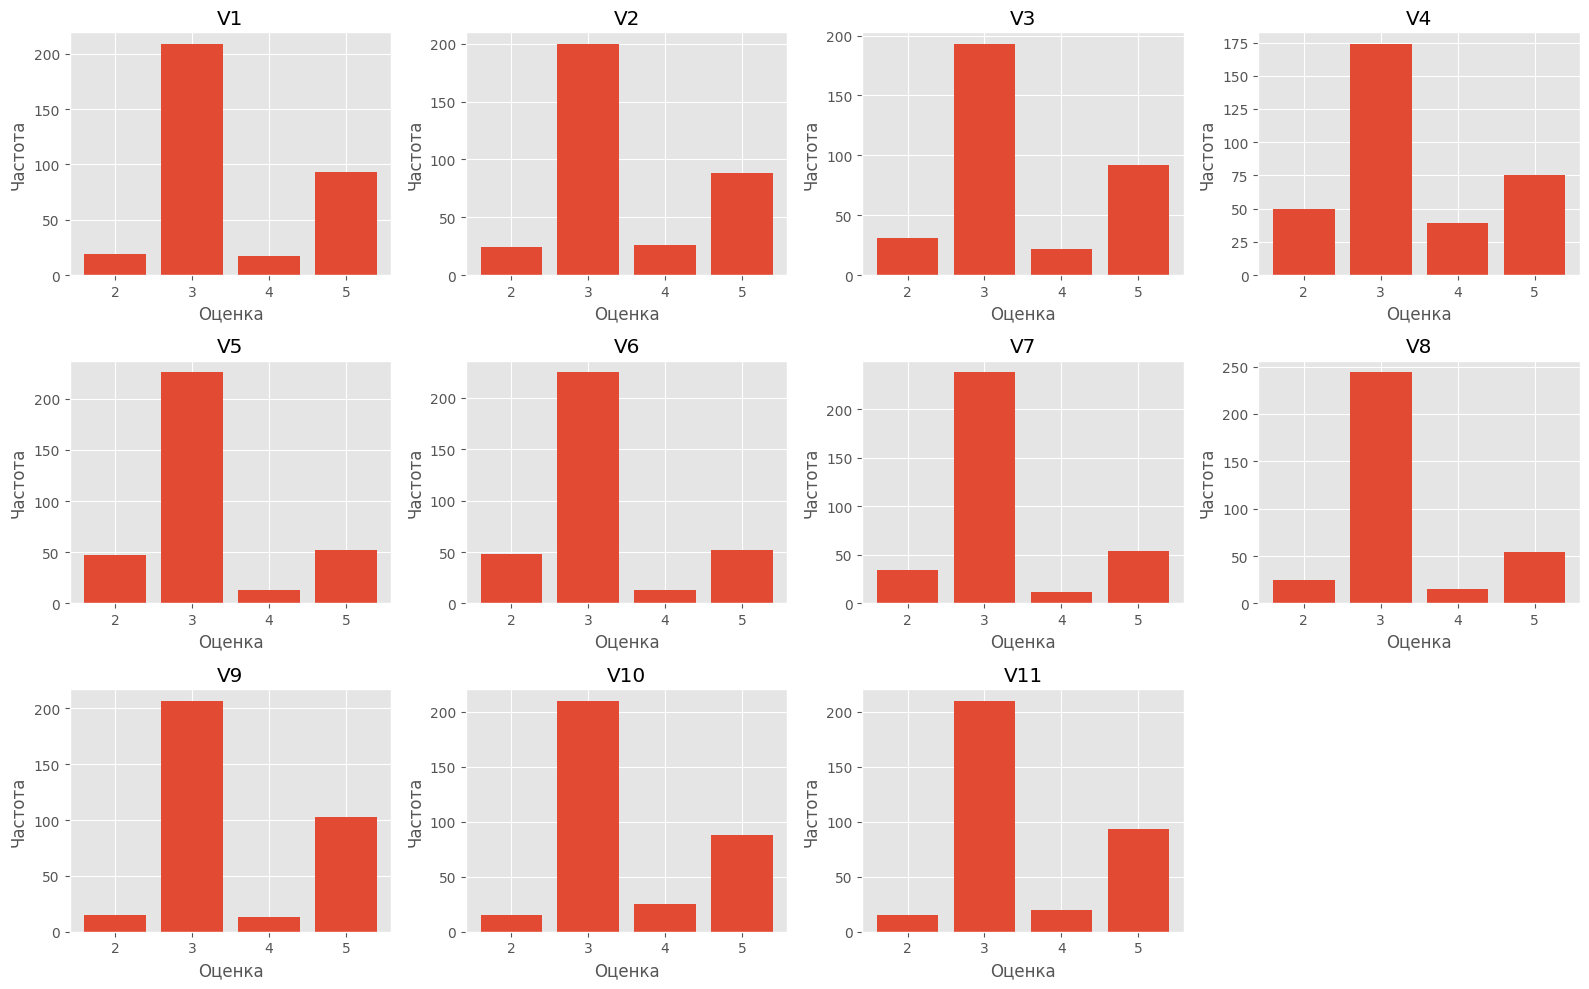

In [8]:
# Гистограммы значений для каждого признака
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.ravel()
for i, col in enumerate(df.columns):
    counts = df[col].value_counts().sort_index()
    axes[i].bar(counts.index, counts.values, )
    axes[i].set_title(col)
    axes[i].set_xticks([2, 3, 4, 5])
    axes[i].set_xlabel('Оценка')
    axes[i].set_ylabel('Частота')
axes[-1].axis('off')
plt.tight_layout()
plt.show()

In [11]:
# Стандартизуем данные
stand = preprocessing.StandardScaler()
# Вычисляем параметры стандартизации
stand.fit(df)
# Преобразуем данные в стандартизированные
x = stand.transform(df)
x = pd.DataFrame(x, index = df.index, columns=df.columns)

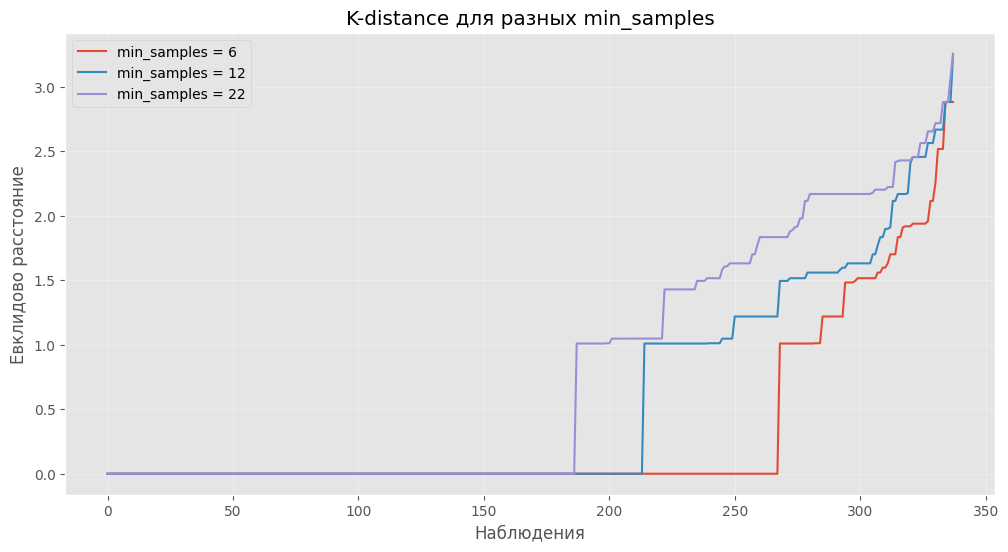

In [47]:
# Рассматриваем три значения min_samples
min_samples_values = [6, 12, 22]

plt.figure(figsize=(12, 6))

for m in min_samples_values:

    # Ищем ближайших соседей
    neighbors = NearestNeighbors(
        n_neighbors=m,
        metric='euclidean'
    )

    neighbors.fit(x)

    # Расстояния до ближайших соседей
    distances, _ = neighbors.kneighbors(x)

    # Сортируем расстояния до m-го соседа
    k_distances = np.sort(distances[:, -1])

    plt.plot(
        k_distances,
        label=f'min_samples = {m}'
    )
# Строим график k-distance
plt.title('K-distance для разных min_samples')
plt.xlabel('Наблюдения')
plt.ylabel('Евклидово расстояние')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

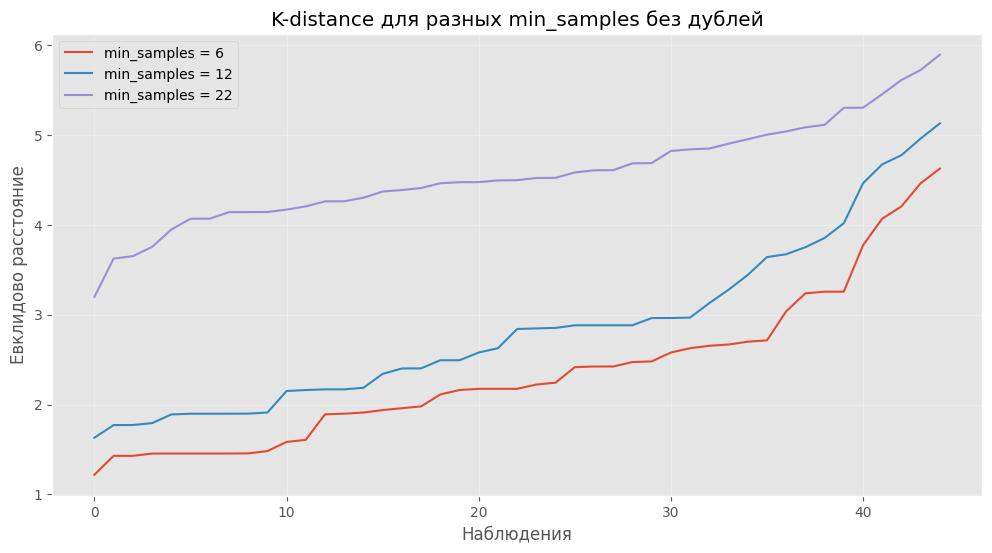

In [45]:
# Аналогично построим k-distance для данных без дубликатов
y = x.drop_duplicates()
min_samples_values = [6, 12, 22]

plt.figure(figsize=(12, 6))

for m in min_samples_values:

    # Ищем ближайших соседей
    neighbors = NearestNeighbors(
        n_neighbors=m,
        metric='euclidean'
    )

    neighbors.fit(y)

    # Расстояния до ближайших соседей
    distances, _ = neighbors.kneighbors(y)

    # Сортируем расстояния до m-го соседа
    k_distances = np.sort(distances[:, -1])

    plt.plot(
        k_distances,
        label=f'min_samples = {m}'
    )
# Строим график k-distance
plt.title('K-distance для разных min_samples без дублей')
plt.xlabel('Наблюдения')
plt.ylabel('Евклидово расстояние')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [43]:
# Проверяем разные сочетания гипер-параметров DBSCAN
eps_values = [1.6, 1.8, 2.0, 2.2, 2.4]
min_samples_values = [6, 12]

results = []

for m in min_samples_values:
    for eps in eps_values:

        model = DBSCAN(
            eps=eps,
            min_samples=m,
            metric='euclidean'
        )

        labels = model.fit_predict(x)

        # Количество кластеров без шума
        n_clusters = len(set(labels) - {-1})

        # Количество шумовых наблюдений
        n_noise = np.sum(labels == -1)

        results.append({
            'min_samples': m,
            'eps': eps,
            'Кластеров': n_clusters,
            'Шумовых объектов': n_noise,
            'Доля шума (%)': round(
                n_noise / len(x) * 100, 2
            )
        })

results_df = pd.DataFrame(results)

display(results_df)

,min_samples,eps,Кластеров,Шумовых объектов,Доля шума (%)
0,6,1.6,9,26,7.69
1,6,1.8,7,18,5.33
2,6,2.0,4,6,1.78
3,6,2.2,4,4,1.18
4,6,2.4,3,4,1.18
5,12,1.6,7,42,12.43
6,12,1.8,6,25,7.40
7,12,2.0,4,10,2.96
8,12,2.2,4,8,2.37
9,12,2.4,3,4,1.18


In [54]:
# Проверим итоговые размеры кластеров при ключевых возможных гипер-параметрах
eps_values = [1.8, 2.2]
min_samples_values = [6, 12]

for min_samples in min_samples_values:
    for eps in eps_values:
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='euclidean'
        )

        labels = model.fit_predict(x)

        print(f'\neps = {eps}, min_samples = {min_samples}')
        print('Количество кластеров:', len(set(labels) - {-1}))

        print('Численность групп:')
        print(pd.Series(labels).value_counts().sort_index())

        print('-' * 45)


eps = 1.8, min_samples = 6
Количество кластеров: 7
Численность групп:
-1     18
 0    105
 1     77
 2     16
 3      7
 4     46
 5     15
 6     54
Name: count, dtype: int64
---------------------------------------------

eps = 2.2, min_samples = 6
Количество кластеров: 4
Численность групп:
-1      4
 0    110
 1    104
 2     61
 3     59
Name: count, dtype: int64
---------------------------------------------

eps = 1.8, min_samples = 12
Количество кластеров: 6
Численность групп:
-1     25
 0    105
 1     77
 2     16
 3     46
 4     15
 5     54
Name: count, dtype: int64
---------------------------------------------

eps = 2.2, min_samples = 12
Количество кластеров: 4
Численность групп:
-1      8
 0    110
 1    100
 2     61
 3     59
Name: count, dtype: int64
---------------------------------------------


In [58]:
# Выбрали параметры DBSCAN
eps = 2.2
min_samples = 6

# Выполняем кластеризацию
dbscan = DBSCAN(
    eps=eps,
    min_samples=min_samples,
    metric='euclidean'
)

clusters = dbscan.fit_predict(x)

# Добавляем метки кластеров к копии данных и считаем среднее
df_clusters = x.copy()
df_clusters['Cluster'] = clusters
cluster_means = df_clusters.groupby('Cluster').mean()

print("Средние значения признаков по кластерам:")
display(cluster_means.round(2))

Средние значения признаков по кластерам:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Cluster,,,,,,,,,,,
-1,-1.62,0.50,0.49,0.59,-1.39,-1.39,-1.49,-0.35,1.44,1.30,1.26
0,1.36,1.33,1.33,1.28,-0.20,-0.19,-0.30,-0.36,-0.55,-0.55,-0.55
1,-0.72,-0.77,-0.81,-0.85,-0.66,-0.69,-0.56,-0.46,1.39,1.37,1.38
2,-0.57,-0.55,-0.52,-0.42,1.90,1.90,-0.30,-0.45,-0.88,-0.86,-0.86
3,-0.57,-0.59,-0.56,-0.50,-0.34,-0.29,1.97,1.98,-0.62,-0.59,-0.60


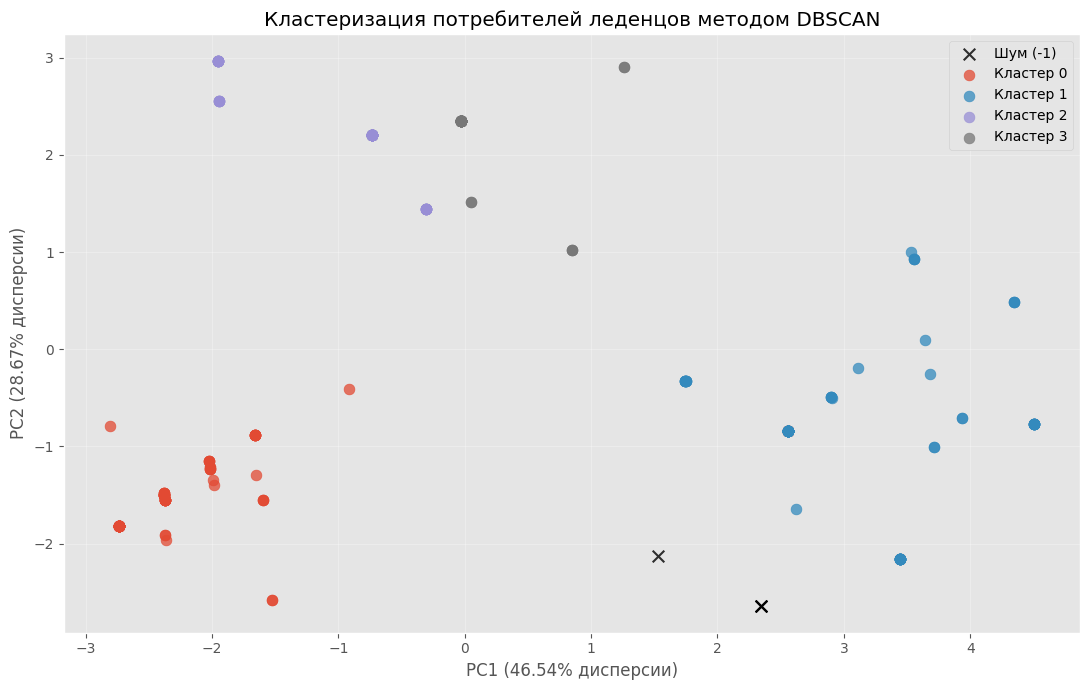

PC1 объясняет 46.54% дисперсии
PC2 объясняет 28.67% дисперсии
Суммарно: 75.21%


In [59]:
# PCA-визуализация итогового варианта DBSCAN
pca = PCA(n_components=2)
X_pca = pca.fit_transform(x)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Cluster'] = clusters.astype(str)

variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(11, 7))

unique_clusters = sorted(pca_df['Cluster'].unique(), key=lambda x: int(x))

for cluster in unique_clusters:
    mask = pca_df['Cluster'] == cluster

    if cluster == '-1':
        plt.scatter(
            pca_df.loc[mask, 'PC1'],
            pca_df.loc[mask, 'PC2'],
            s=70,
            c='black',
            marker='x',
            label='Шум (-1)',
            alpha=0.8
        )
    else:
        plt.scatter(
            pca_df.loc[mask, 'PC1'],
            pca_df.loc[mask, 'PC2'],
            s=60,
            alpha=0.75,
            label=f'Кластер {cluster}'
        )

plt.title('Кластеризация потребителей леденцов методом DBSCAN')
plt.xlabel(f'PC1 ({variance[0]:.2f}% дисперсии)')
plt.ylabel(f'PC2 ({variance[1]:.2f}% дисперсии)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'PC1 объясняет {variance[0]:.2f}% дисперсии')
print(f'PC2 объясняет {variance[1]:.2f}% дисперсии')
print(f'Суммарно: {variance.sum():.2f}%')

In [60]:
# Выделяем шумовые наблюдения
noise = x.loc[clusters == -1].copy().round(3)

# Сохраняем номера исходных строк
noise.insert(0, 'Номер наблюдения', noise.index + 1)

print("Количество шумовых объектов:", len(noise))
display(noise)

# Средние значения признаков для шума
print("\nСредние значения признаков шумовых объектов:")
display(noise.drop(columns='Номер наблюдения').mean().round(2))

Количество шумовых объектов: 4


,Номер наблюдения,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
112,113,-1.618,0.496,0.488,0.594,-1.394,-1.387,-1.488,-0.353,1.442,1.566,1.525
139,140,-1.618,0.496,0.488,0.594,-1.394,-1.387,-1.488,-0.353,1.442,1.566,1.525
177,178,-1.618,0.496,0.488,0.594,-1.394,-1.387,-1.488,-0.353,1.442,0.486,0.462
188,189,-1.618,0.496,0.488,0.594,-1.394,-1.387,-1.488,-0.353,1.442,1.566,1.525



Средние значения признаков шумовых объектов:


,0
V1,-1.62
V2,0.50
V3,0.49
V4,0.59
V5,-1.39
V6,-1.39
V7,-1.49
V8,-0.35
V9,1.44
V10,1.30
